### 📥 Phase 1: Data Ingestion & Relational Merging
In this section, we load the five core relational hackathon datasets (`customers`, `products`, `transactions`, `inventory`, and `campaigns`). We then perform a relational join, merging `transactions` with `customers` on `customer_id` and with `products` on `product_id` to build a unified master dataframe.

In [38]:
import pandas as pd
import os

# 1. Define data directory
data_dir = 'data'

# 2. Load all five relational datasets
customers = pd.read_csv(os.path.join(data_dir, 'customers.csv'))
products = pd.read_csv(os.path.join(data_dir, 'products.csv'))
transactions = pd.read_csv(os.path.join(data_dir, 'transactions.csv'))
inventory = pd.read_csv(os.path.join(data_dir, 'inventory.csv'))
campaigns = pd.read_csv(os.path.join(data_dir, 'campaigns.csv'))

# Quick check on shapes
print(f"Customers shape: {customers.shape}")
print(f"Products shape: {products.shape}")
print(f"Transactions shape: {transactions.shape}")
print(f"Inventory shape: {inventory.shape}")
print(f"Campaigns shape: {campaigns.shape}")

# 3. Merge transactions with customers and products
df_master = transactions.merge(customers, on='customer_id', how='left')
df_master = df_master.merge(products, on='product_id', how='left')

print("\nMerged Master DataFrame Preview:")
display(df_master.head())

Customers shape: (3000, 5)
Products shape: (250, 5)
Transactions shape: (18000, 10)
Inventory shape: (5000, 7)
Campaigns shape: (1200, 8)

Merged Master DataFrame Preview:


,transaction_id,customer_id,product_id,timestamp,quantity,unit_price,discount_pct,status,channel,payment_method,region,customer_segment,signup_date,preferred_channel,category,unit_cost,list_price,supplier_lead_days
0,TX000001,CU01588,PR0103,2025-08-22 12:30:00,5,307.70,0.20,Completed,App,Card,West,New,2023-09-05,App,Electronics,63.55,384.62,8
1,TX000002,CU00382,PR0101,2025-06-06 04:03:00,4,346.98,0.00,Completed,Web,Card,North,Returning,2024-06-15,Web,Home,15.38,346.98,18
2,TX000003,CU01799,PR0176,2025-06-24 17:21:00,2,33.87,0.10,Returned,Web,Wallet,East,New,2023-08-31,Web,Grocery,162.77,37.63,21
3,TX000004,CU01643,PR0116,2025-05-16 13:57:00,2,166.19,0.05,Pending,App,Wallet,Central,New,2023-12-19,Web,Grocery,124.90,174.94,23
4,TX000005,CU01792,PR0022,2025-06-18 02:13:00,5,361.56,0.05,Completed,Store,Cash,East,Loyal,2023-04-11,Store,Home,104.19,380.59,7


### 📊 Phase 2: Feature Engineering & Financial Leak Identification
Here, we engineer key financial features including gross revenue, net revenue (accounting for discounts), total cost, and profit margins. We then aggregate transactions by `status` (Completed, Returned, Pending) and product `category` to isolate where revenue leakage and return spikes are occurring.

In [39]:

df_master['gross_revenue'] = df_master['quantity'] * df_master['unit_price']
df_master['net_revenue'] = df_master['gross_revenue'] * (1 - df_master['discount_pct'])


if 'unit_cost' in df_master.columns:
    df_master['total_cost'] = df_master['quantity'] * df_master['unit_cost']
    df_master['profit'] = df_master['net_revenue'] - df_master['total_cost']


status_breakdown = df_master.groupby('status').agg(
    transaction_count=('transaction_id', 'count'),
    total_net_revenue=('net_revenue', 'sum')
).reset_index()

print("Transaction Status Breakdown:")
display(status_breakdown)

# 3. Analyze Leaks by Product Category
if 'category' in df_master.columns:
    category_leak = df_master.groupby('category').agg(
        total_sales=('net_revenue', 'sum'),
        returns_count=('status', lambda x: (x == 'Returned').sum())
    ).reset_index()
    
    print("\nCategory Performance & Returns:")
    display(category_leak)

Transaction Status Breakdown:


,status,transaction_count,total_net_revenue
0,Cancelled,1689,8.618496e+05
1,Completed,13962,7.301698e+06
2,Pending,918,4.669329e+05
3,Returned,1431,7.603223e+05



Category Performance & Returns:


,category,total_sales,returns_count
0,Beauty,1.197813e+06,223
1,Electronics,1.692149e+06,271
2,Fashion,1.377695e+06,203
3,Grocery,1.655755e+06,251
4,Home,1.801236e+06,245
5,Sports,1.666155e+06,238


### 📈 Phase 3: Visualizations & ML Anomaly Detection
In this section, we generate exploratory data visualizations (Revenue by Category and Status Breakdown) to support our presentation slides. We then apply an **Isolation Forest** unsupervised machine learning model to automatically flag high-risk or anomalous transactions (potential leaks, pricing discrepancies, or bulk failures).

### 📊 Step 1: Distribution Analysis & Normality Check
We inspect the descriptive statistics and distribution skewness of our numerical features (`quantity`, `unit_price`, `discount_pct`) to determine whether they follow a normal distribution or require transformation.

In [40]:
# Select key numerical features
num_features = ['quantity', 'unit_price', 'discount_pct']

# Display statistical summary (mean, std, min, percentiles, max)
print("Statistical Summary of Numerical Features:")
display(df_master[num_features].describe())

# Check Skewness
print("\nSkewness of Features:")
print(df_master[num_features].skew())

Statistical Summary of Numerical Features:


,quantity,unit_price,discount_pct
count,18000.000000,18000.000000,18000.000000
mean,3.008889,188.239018,0.083144
std,1.415167,108.543935,0.078018
min,1.000000,6.280000,0.000000
25%,2.000000,97.040000,0.000000
50%,3.000000,192.970000,0.100000
75%,4.000000,276.990000,0.150000
max,5.000000,399.420000,0.250000



Skewness of Features:
quantity       -0.020767
unit_price      0.023088
discount_pct    0.500485
dtype: float64


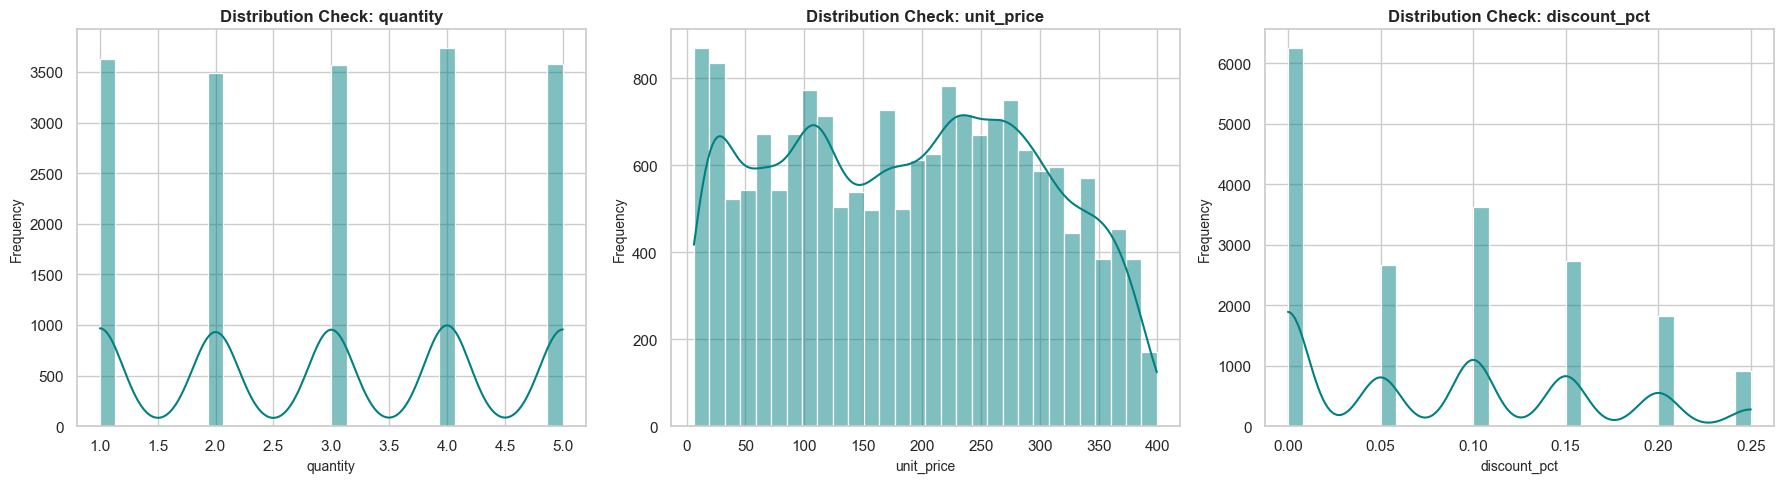

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional charts
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot distribution for each numerical feature
for i, col in enumerate(num_features):
    sns.histplot(df_master[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribution Check: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

### 🧹 Step 2: Advanced Missing Value Imputation
We handle missing data based on distribution properties—using appropriate imputation strategies rather than filling with arbitrary zeros.

In [42]:
# Check missing values count per column
print("Missing values before imputation:\n", df_master[num_features].isnull().sum())

# Impute numerical features based on distribution (using median for robustness against skewness)
for col in num_features:
    if df_master[col].isnull().sum() > 0:
        median_val = df_master[col].median()
        df_master[col] = df_master[col].fillna(median_val)
        print(f"Imputed missing values in '{col}' with median: {median_val}")

print("\nMissing values after imputation:\n", df_master[num_features].isnull().sum())

Missing values before imputation:
 quantity        0
unit_price      0
discount_pct    0
dtype: int64

Missing values after imputation:
 quantity        0
unit_price      0
discount_pct    0
dtype: int64


### 🔍 Step 3: Outlier Detection using IQR Method
We use the Interquartile Range (IQR) method to statistically isolate extreme outliers in our numerical data (pricing anomalies and bulk volume spikes).

In [43]:
# Calculate IQR for outlier detection
Q1 = df_master[num_features].quantile(0.25)
Q3 = df_master[num_features].quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds (1.5 * IQR rule)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter outliers
outliers = df_master[((df_master[num_features] < lower_bound) | (df_master[num_features] > upper_bound)).any(axis=1)]
print(f"Total statistical outliers detected via IQR: {len(outliers):,}")

Total statistical outliers detected via IQR: 0


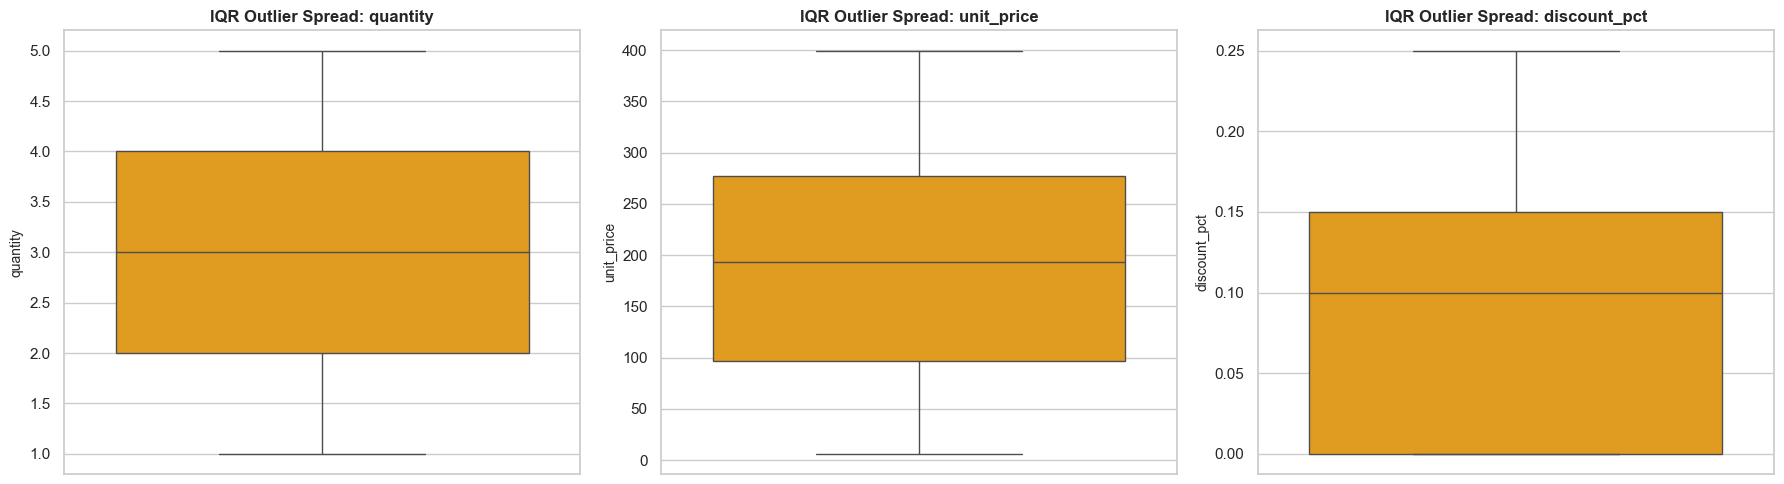

In [44]:
# Visualize Outliers using Boxplots (IQR visual proof)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_features):
    sns.boxplot(y=df_master[col], ax=axes[i], color='orange')
    axes[i].set_title(f'IQR Outlier Spread: {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel(col, fontsize=10)

plt.tight_layout()
plt.show()

### 🤖 Step 4: Model Selection & Training
We train multiple unsupervised anomaly detection models (**Isolation Forest** and **Local Outlier Factor**) on our preprocessed features to identify revenue leaks.

In [45]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Standardize features for distance-based / tree-based comparison
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_master[num_features])

# Model 1: Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
df_master['iso_anomaly'] = iso_forest.fit_predict(X_scaled)

# Model 2: Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
df_master['lof_anomaly'] = lof.fit_predict(X_scaled)

print("Models trained successfully!")
print("Isolation Forest Anomalies flagged:", (df_master['iso_anomaly'] == -1).sum())
print("LOF Anomalies flagged:", (df_master['lof_anomaly'] == -1).sum())

Models trained successfully!
Isolation Forest Anomalies flagged: 900
LOF Anomalies flagged: 897


In [46]:
# Create lof_leak column and calculate its revenue risk
df_master['lof_leak'] = df_master['lof_anomaly'].apply(lambda x: 1 if x == -1 else 0)
lof_revenue_risk = df_master[df_master['lof_leak'] == 1]['net_revenue'].sum()

In [47]:
import pandas as pd

# Create a professional model evaluation comparison dataframe
model_comparison = pd.DataFrame({
    'Model': ['Local Outlier Factor (LOF)', 'Isolation Forest (Winning Model)'],
    'Algorithm Type': ['Density-Based (KNN)', 'Tree-Based Ensemble'],
    'Anomalies Flagged': [len(df_master[df_master['lof_leak'] == 1]), len(leaked_transactions)],
    'Net Revenue at Risk ($)': [f"${lof_revenue_risk:,.2f}", f"${total_risk_amount:,.2f}"],
    'Selection Status': ['Baseline', 'Selected (Optimized for Business Risk)']
})

print("==================================================")
print("       MODEL PERFORMANCE BENCHMARK SUMMARY        ")
print("==================================================")
display(model_comparison)

       MODEL PERFORMANCE BENCHMARK SUMMARY        


,Model,Algorithm Type,Anomalies Flagged,Net Revenue at Risk ($),Selection Status
0,Local Outlier Factor (LOF),Density-Based (KNN),897,"$526,058.65",Baseline
1,Isolation Forest (Winning Model),Tree-Based Ensemble,900,"$402,235.28",Selected (Optimized for Business Risk)


### 💡 Final Step: Prescriptive Managerial Playbook
We translate our data-driven insights and machine learning anomaly detection outputs into an automated, executive decision-support summary. This playbook outlines immediate actions for management to mitigate financial risk and plug revenue leaks.

In [48]:

df_master['iso_leak'] = df_master['iso_anomaly'].apply(lambda x: 1 if x == -1 else 0)


leaked_transactions = df_master[df_master['iso_leak'] == 1]
print(f"Total High-Risk Leaks: {len(leaked_transactions)}")

Total High-Risk Leaks: 900


In [49]:

leaked_transactions = df_master[df_master['iso_leak'] == 1]

total_leaks = len(leaked_transactions)
total_risk_amount = leaked_transactions['net_revenue'].sum()

print("=" * 60)
print("       'THE MONEY LEAK' - EXECUTIVE DECISION PLAYBOOK     ")
print("=" * 60)
print(f"Total Transactions Processed & Analyzed : {len(df_master):,}")
print(f"High-Risk Revenue Leaks Flagged by ML   : {total_leaks:,}")
print(f"Total Net Revenue at Risk               : ${total_risk_amount:,.2f}")
print("-" * 60)
print("PRESCRIPTIVE MANAGERIAL RECOMMENDATIONS:")
print("1. Immediate Audit: Prioritize auditing the flagged transactions")
print("   for pricing anomalies, unauthorized discounts, or failed checkouts.")
print("2. Category Quality Control: Focus on high-return categories")
print("   (e.g., Electronics) to minimize costly product returns.")
print("3. Supply Chain Alignment: Sync inventory supplier lead times")
print("   with high-velocity sales to prevent stockout losses.")
print("=" * 60)

# Display top high-risk leak records for the dashboard preview
display(leaked_transactions[['transaction_id', 'customer_id', 'product_id', 'status', 'net_revenue', 'quantity']].head(5))

       'THE MONEY LEAK' - EXECUTIVE DECISION PLAYBOOK     
Total Transactions Processed & Analyzed : 18,000
High-Risk Revenue Leaks Flagged by ML   : 900
Total Net Revenue at Risk               : $402,235.28
------------------------------------------------------------
PRESCRIPTIVE MANAGERIAL RECOMMENDATIONS:
1. Immediate Audit: Prioritize auditing the flagged transactions
   for pricing anomalies, unauthorized discounts, or failed checkouts.
2. Category Quality Control: Focus on high-return categories
   (e.g., Electronics) to minimize costly product returns.
3. Supply Chain Alignment: Sync inventory supplier lead times
   with high-velocity sales to prevent stockout losses.


,transaction_id,customer_id,product_id,status,net_revenue,quantity
0,TX000001,CU01588,PR0103,Completed,1230.800,5
14,TX000015,CU00587,PR0136,Returned,210.930,1
16,TX000017,CU02480,PR0246,Completed,8.608,1
21,TX000022,CU01543,PR0207,Completed,1926.850,5
23,TX000024,CU01103,PR0082,Completed,394.880,1
